# Aula 2 — Otimizando a classificação de gatos, cachorros e pandas com MobileNetV2

**TensorFlow + Keras | Transfer Learning e Fine-tuning | Google Colab**

Na aula anterior, construímos uma CNN do zero. A acurácia reportada foi de aproximadamente **74%** no primeiro experimento e **70,22%** após Data Augmentation; as curvas indicaram sobreajuste. Agora investigaremos **transferência de aprendizado**.

**Objetivos:** (1) compreender a diferença entre treinar do zero e reutilizar uma CNN; (2) congelar a base MobileNetV2 e treinar um novo classificador; (3) comparar curvas e métricas de validação; (4) opcionalmente realizar *fine-tuning*; (5) avaliar **uma única vez**, ao final, no conjunto de teste.

> Não há garantia de melhora: os resultados dependem das imagens, do treinamento e da divisão de dados. Mantenha a mesma divisão da aula anterior para comparar os modelos.

## 1. Relembrando a primeira aula

- **CNN do zero:** aprende filtros convolucionais a partir das nossas 1.050 imagens de treinamento.
- **Transfer Learning:** aproveita filtros de uma CNN treinada anteriormente em um grande conjunto de imagens (ImageNet); treinamos inicialmente apenas uma nova cabeça classificadora.
- **Fine-tuning:** descongela uma pequena parte da base e ajusta os pesos com uma taxa de aprendizado menor.

**Questão para discussão:** por que aproveitar representações visuais pré-treinadas pode ajudar quando nosso dataset é pequeno?

## 2. Bibliotecas e reprodutibilidade

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

# Para que os experimentos possam ser reproduzidos (até onde o hardware permitir).
SEMENTE = 42
keras.utils.set_random_seed(SEMENTE)
print('TensorFlow:', tf.__version__)
print('GPUs disponíveis:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs disponíveis: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Montar o Drive e localizar o mesmo dataset

Mantemos `knnsvmtest_dividido/treino`, `validacao` e `teste` e as mesmas classes, na mesma ordem. Não mova imagens entre os conjuntos.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PASTA_DADOS = Path('/content/drive/MyDrive/knnsvmtest_dividido')
CLASSES = ['cats', 'dogs', 'panda']
PARTES = ['treino', 'validacao', 'teste']

for parte in PARTES:
    for classe in CLASSES:
        pasta = PASTA_DADOS / parte / classe
        if not pasta.is_dir():
            raise FileNotFoundError(f'Pasta não encontrada: {pasta}')
print('Estrutura de pastas encontrada:', PASTA_DADOS)

Mounted at /content/drive
Estrutura de pastas encontrada: /content/drive/MyDrive/knnsvmtest_dividido


## 4. Conferir a quantidade de imagens por classe

In [ ]:
EXTENSOES = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
linhas = []
for parte in PARTES:
    for classe in CLASSES:
        arquivos = [p for p in (PASTA_DADOS / parte / classe).iterdir()
                    if p.is_file() and p.suffix.lower() in EXTENSOES]
        linhas.append({'conjunto': parte, 'classe': classe, 'quantidade': len(arquivos)})
contagem = pd.DataFrame(linhas)
display(contagem.pivot(index='conjunto', columns='classe', values='quantidade').reindex(PARTES))
print('Total de imagens:', contagem['quantidade'].sum())
assert (contagem['quantidade'] > 0).all(), 'Há alguma classe vazia!'
# Esperado no experimento anterior: 350/75/75 por classe, mas não forçamos
# esses valores para permitir reutilizar a estrutura caso haja ajustes.

classe,cats,dogs,panda
conjunto,,,
treino,350,350,350
validacao,75,75,75
teste,75,75,75


Total de imagens: 1500


## 5. Carregar as imagens RGB

A MobileNetV2 costuma trabalhar com imagens maiores que as da CNN anterior. Aqui usamos **160 × 160 pixels**, sem alterar quais imagens pertencem a cada conjunto. O carregador retorna pixels de **0 a 255**. Não use `Rescaling(1./255)` no dataset: o pré-processamento específico da MobileNetV2 será aplicado **dentro do modelo**.

In [ ]:
TAMANHO_IMAGEM = (160, 160)
BATCH_SIZE = 32

# Importante: não embaralhar validação e teste, para manter previsões e
# rótulos na mesma ordem ao calcular as métricas e a matriz de confusão.
def carregar_conjunto(nome, embaralhar):
    return keras.utils.image_dataset_from_directory(
        PASTA_DADOS / nome,
        labels='inferred',
        label_mode='int',
        class_names=CLASSES,
        image_size=TAMANHO_IMAGEM,
        batch_size=BATCH_SIZE,
        shuffle=embaralhar,
        seed=SEMENTE
    )

treino_ds = carregar_conjunto('treino', True)
validacao_ds = carregar_conjunto('validacao', False)
teste_ds = carregar_conjunto('teste', False)

# Acelera a preparação dos lotes sem carregar obrigatoriamente tudo na RAM.
AUTOTUNE = tf.data.AUTOTUNE
treino_ds = treino_ds.prefetch(AUTOTUNE)
validacao_ds = validacao_ds.prefetch(AUTOTUNE)
teste_ds = teste_ds.prefetch(AUTOTUNE)

Found 1050 files belonging to 3 classes.
Found 225 files belonging to 3 classes.
Found 225 files belonging to 3 classes.


## 6. Visualizar as imagens de entrada

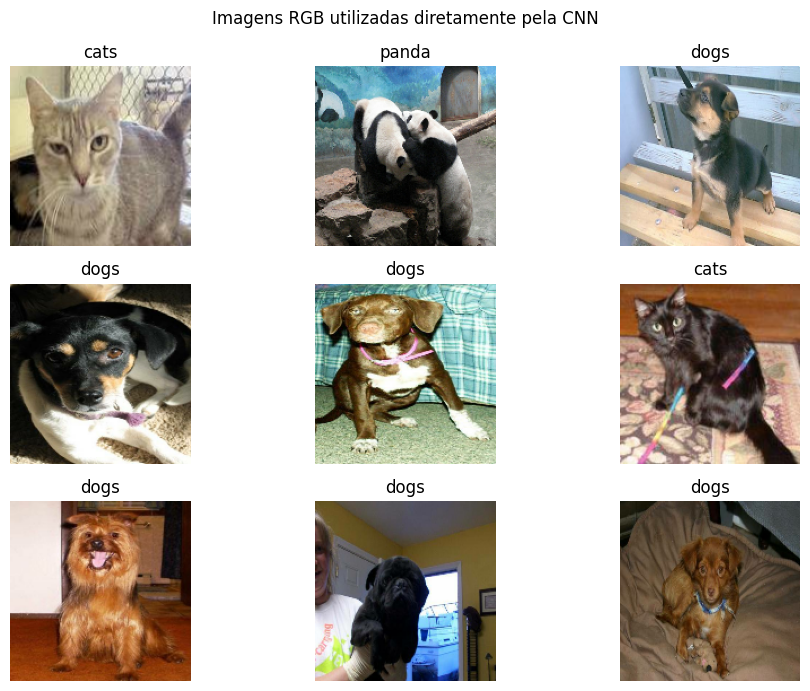

In [ ]:
plt.figure(figsize=(10, 7))
for imagens, rotulos in treino_ds.take(1):
    for i in range(min(9, len(imagens))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imagens[i].numpy().astype('uint8'))
        plt.title(CLASSES[int(rotulos[i])])
        plt.axis('off')
plt.suptitle('Imagens RGB utilizadas diretamente pela CNN')
plt.tight_layout()
plt.show()

## 7. Data Augmentation (somente durante o treinamento)

Pequenas alterações aleatórias podem ajudar a generalizar. Como as camadas estão **dentro do modelo**, são aplicadas no treinamento e desativadas automaticamente em validação, teste e `predict`. Para um experimento sem augmentation, basta substituir o bloco por `keras.Sequential([], name="Data_Augmentation")` e reconstruir o modelo.

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.08),
], name='Data_Augmentation')

# Não há aumento permanente do número de arquivos no Drive.


## 8. Construir o modelo: MobileNetV2 congelada + novo classificador

A base MobileNetV2 foi pré-treinada no **ImageNet**. Com `include_top=False`, retiramos o classificador original. A base produz **mapas de características**, que são resumidos por `GlobalAveragePooling2D`. A nova camada `Dense(3, softmax)` aprende nossas três classes.

**Atenção à escala dos pixels:** `mobilenet_v2.preprocess_input` transforma RGB de **0–255 para aproximadamente −1 a +1**. Não aplique também `Rescaling(1./255)`. Usamos `base(x, training=False)` para manter as camadas BatchNormalization da base no modo de inferência, inclusive no fine-tuning.

In [ ]:
# Na primeira execução, o Colab fará download dos pesos do ImageNet.
base = keras.applications.MobileNetV2(
    input_shape=(*TAMANHO_IMAGEM, 3),
    include_top=False,
    weights='imagenet'
)
base.trainable = False  # Etapa 1: congelar TODAS as camadas da base.

entradas = keras.Input(shape=(*TAMANHO_IMAGEM, 3), name='Imagem_RGB')
x = data_augmentation(entradas)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D(name='Resumo_dos_Mapas')(x)
x = layers.Dropout(0.30)(x)
saidas = layers.Dense(len(CLASSES), activation='softmax', name='Tres_Classes')(x)

modelo = keras.Model(entradas, saidas, name='MobileNetV2_Animais')
modelo.summary()
print('Parâmetros treináveis na etapa 1:', sum(int(np.prod(v.shape)) for v in modelo.trainable_weights))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_Animais"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Imagem_RGB (InputLayer)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Data_Augmentation (Sequential)  │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Resumo_dos_Mapas                │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Tres_Classes (Dense)            │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Parâmetros treináveis na etapa 1: 3843


## 9. Compilar o modelo

Como os rótulos são números inteiros (`0`, `1`, `2`), usamos `sparse_categorical_crossentropy`. A taxa de aprendizado inicial é `1e-3` porque só treinaremos a cabeça classificadora.

In [ ]:
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 10. Treinamento da cabeça classificadora

`ModelCheckpoint` salva o modelo de menor **perda de validação**; `EarlyStopping` interrompe se a validação não melhorar. Não avaliamos o teste nesta etapa.

In [ ]:
ARQUIVO_ETAPA1 = '/content/mobilenetv2_animais_etapa1.keras'
callbacks_etapa1 = [
    keras.callbacks.ModelCheckpoint(ARQUIVO_ETAPA1, monitor='val_loss',
                                    mode='min', save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=5,
                                  restore_best_weights=True, verbose=1)
]

historico = modelo.fit(
    treino_ds, validation_data=validacao_ds,
    epochs=25, callbacks=callbacks_etapa1
)

Epoch 1/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6079 - loss: 0.9536
Epoch 1: val_loss improved from None to 0.16508, saving model to /content/mobilenetv2_animais_etapa1.keras

Epoch 1: finished saving model to /content/mobilenetv2_animais_etapa1.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 161s 5s/step - accuracy: 0.7743 - loss: 0.5891 - val_accuracy: 0.9600 - val_loss: 0.1651
Epoch 2/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.9311 - loss: 0.1875
Epoch 2: val_loss improved from 0.16508 to 0.11135, saving model to /content/mobilenetv2_animais_etapa1.keras

Epoch 2: finished saving model to /content/mobilenetv2_animais_etapa1.keras
33/33 ━━━━━━━━━━━━━━━━━━━━ 4s 118ms/step - accuracy: 0.9429 - loss: 0.1582 - val_accuracy: 0.9778 - val_loss: 0.1113
Epoch 3/25
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.9455 - loss: 0.1315
Epoch 3: val_loss improved from 0.11135 to 0.10423, saving model to /content/mobilenetv2_animais_etapa1.keras

Epoch 3: finished saving model t

## 11. Gráficos da etapa 1 — acurácia e perda

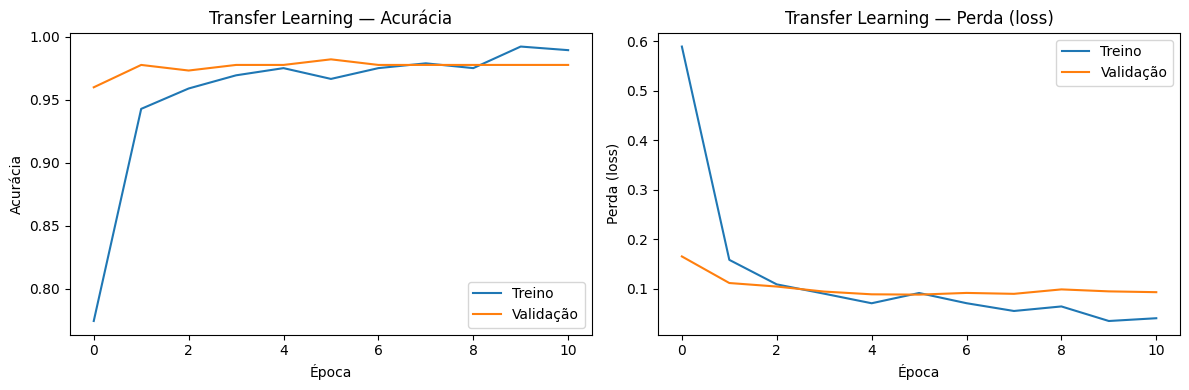

In [ ]:
def mostrar_curvas(h, titulo):
    fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
    for ax, chave, rotulo in zip(eixos, ['accuracy', 'loss'], ['Acurácia', 'Perda (loss)']):
        ax.plot(h.history[chave], label='Treino')
        ax.plot(h.history['val_' + chave], label='Validação')
        ax.set(title=f'{titulo} — {rotulo}', xlabel='Época', ylabel=rotulo)
        ax.legend()
    plt.tight_layout()
    plt.show()

mostrar_curvas(historico, 'Transfer Learning')

## 12. Validação da etapa 1

Carregamos o **melhor checkpoint**, não necessariamente o da última época. Essa avaliação usa apenas o conjunto de validação. A seleção final entre etapa 1 e etapa 2 será feita **sem consultar o teste**.

In [ ]:
modelo_etapa1 = keras.models.load_model(ARQUIVO_ETAPA1)
perda_val_1, acuracia_val_1 = modelo_etapa1.evaluate(validacao_ds, verbose=0)
print(f'Etapa 1 — validação: perda={perda_val_1:.4f}, acurácia={acuracia_val_1:.4f}')

Etapa 1 — validação: perda=0.0879, acurácia=0.9822


## 13. Fine-tuning opcional: ajustar as últimas camadas da MobileNetV2

Na etapa 1, **apenas a cabeça** aprendeu. Agora descongelamos as últimas **30 camadas** da base (mantendo `BatchNormalization` congeladas) e treinamos com taxa de aprendizado **muito menor (`1e-5`)**. É essencial **recompilar** o modelo após alterar `trainable`.

Se preferir uma aula dedicada só a Transfer Learning, pule esta seção e siga para a seção 16; o notebook escolherá automaticamente o modelo da etapa 1.

In [ ]:
EXECUTAR_FINE_TUNING = False  # Altere para False para estudar apenas a etapa 1.

if EXECUTAR_FINE_TUNING:
    # Partimos do melhor checkpoint da etapa 1, e não dos pesos da última época.
    modelo = keras.models.load_model(ARQUIVO_ETAPA1)
    base_ft = next(camada for camada in modelo.layers
                   if isinstance(camada, keras.Model) and 'mobilenetv2' in camada.name.lower())
    base_ft.trainable = True
    # Congelar tudo, exceto as últimas 30 camadas; BN permanece congelada.
    for camada in base_ft.layers[:-30]:
        camada.trainable = False
    for camada in base_ft.layers[-30:]:
        camada.trainable = not isinstance(camada, layers.BatchNormalization)

    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    print('Parâmetros treináveis no fine-tuning:',
          sum(int(np.prod(v.shape)) for v in modelo.trainable_weights))
else:
    print('Fine-tuning desativado. Prosseguiremos com a etapa 1.')

Fine-tuning desativado. Prosseguiremos com a etapa 1.


## 14. Treinar a etapa de Fine-tuning (opcional)

In [ ]:
ARQUIVO_ETAPA2 = '/content/mobilenetv2_animais_finetuning.keras'
historico_ft = None
if EXECUTAR_FINE_TUNING:
    callbacks_etapa2 = [
        keras.callbacks.ModelCheckpoint(ARQUIVO_ETAPA2, monitor='val_loss',
                                        mode='min', save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=5,
                                      restore_best_weights=True, verbose=1)
    ]
    historico_ft = modelo.fit(treino_ds, validation_data=validacao_ds,
                             epochs=15, callbacks=callbacks_etapa2)
else:
    print('Etapa 2 ignorada.')

Etapa 2 ignorada.


## 15. Comparar as etapas usando apenas validação

In [ ]:
resultados_validacao = [
    {'Modelo': 'MobileNetV2 congelada', 'val_loss': perda_val_1,
     'val_accuracy': acuracia_val_1, 'arquivo': ARQUIVO_ETAPA1}
]
if EXECUTAR_FINE_TUNING:
    mostrar_curvas(historico_ft, 'Fine-tuning')
    modelo_etapa2 = keras.models.load_model(ARQUIVO_ETAPA2)
    perda_val_2, acuracia_val_2 = modelo_etapa2.evaluate(validacao_ds, verbose=0)
    resultados_validacao.append({
        'Modelo': 'MobileNetV2 fine-tuning', 'val_loss': perda_val_2,
        'val_accuracy': acuracia_val_2, 'arquivo': ARQUIVO_ETAPA2
    })

comparacao = pd.DataFrame(resultados_validacao)
print(comparacao[['Modelo', 'val_loss', 'val_accuracy']].to_string(index=False))
# Critério coerente com os checkpoints: menor perda de validação.
melhor = min(resultados_validacao, key=lambda item: item['val_loss'])
print('Modelo selecionado pela menor perda de validação:', melhor['Modelo'])
modelo = keras.models.load_model(melhor['arquivo'])

               Modelo  val_loss  val_accuracy
MobileNetV2 congelada  0.087899      0.982222
Modelo selecionado pela menor perda de validação: MobileNetV2 congelada


## 16. Avaliação FINAL — conjunto de teste

**Execute esta seção somente depois de decidir a configuração usando a validação.** O conjunto de teste deve ser reservado para a estimativa final de desempenho; não escolha novas configurações com base neste resultado. Calcularemos acurácia, precisão, recall e F1 macro.

In [ ]:
# Recupera todos os rótulos verdadeiros do conjunto de teste.
y_real = np.concatenate([rotulos.numpy() for _, rotulos in teste_ds])

# Prediz probabilidades para cada uma das três classes.
probabilidades = modelo.predict(teste_ds, verbose=0)
y_previsto = np.argmax(probabilidades, axis=1)

acuracia = accuracy_score(y_real, y_previsto)
precisao, recall, f1, _ = precision_recall_fscore_support(
    y_real, y_previsto, average='macro', zero_division=0
)

print('AVALIAÇÃO FINAL — MobileNetV2 com imagens RGB')
print(f'Acurácia:       {acuracia:.4f}')
print(f'Precisão macro: {precisao:.4f}')
print(f'Recall macro:   {recall:.4f}')
print(f'F1 macro:      {f1:.4f}')
print()
print('Relatório por classe:')
print(classification_report(y_real, y_previsto, labels=[0, 1, 2],
                            target_names=CLASSES, zero_division=0))

AVALIAÇÃO FINAL — MobileNetV2 com imagens RGB
Acurácia:       0.9956
Precisão macro: 0.9956
Recall macro:   0.9956
F1 macro:      0.9956

Relatório por classe:
              precision    recall  f1-score   support

        cats       0.99      1.00      0.99        75
        dogs       1.00      0.99      0.99        75
       panda       1.00      1.00      1.00        75

    accuracy                           1.00       225
   macro avg       1.00      1.00      1.00       225
weighted avg       1.00      1.00      1.00       225



## 17. Matriz de confusão no teste

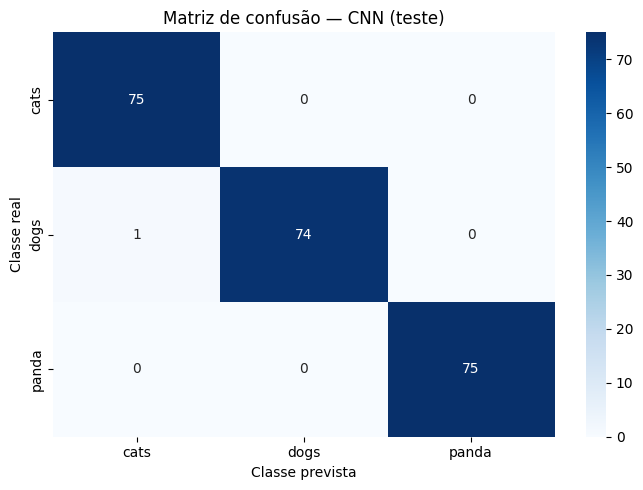

In [ ]:
matriz = confusion_matrix(y_real, y_previsto, labels=[0, 1, 2])
plt.figure(figsize=(7, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Classe prevista')
plt.ylabel('Classe real')
plt.title('Matriz de confusão — CNN (teste)')
plt.tight_layout()
plt.show()

## 18. Visualizar previsões em imagens do teste

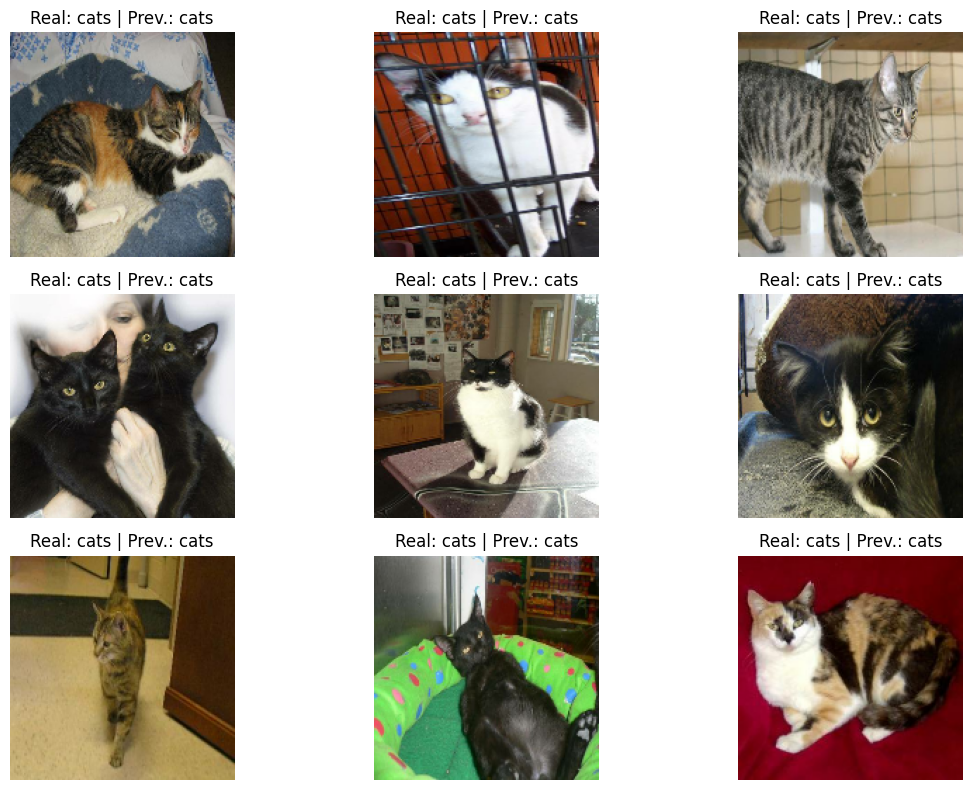

In [ ]:
plt.figure(figsize=(12, 8))
for imagens, rotulos in teste_ds.take(1):
    prob_lote = modelo.predict(imagens, verbose=0)
    pred_lote = np.argmax(prob_lote, axis=1)
    for i in range(min(9, len(imagens))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(imagens[i].numpy().astype('uint8'))
        real = CLASSES[int(rotulos[i])]
        previsto = CLASSES[int(pred_lote[i])]
        plt.title(f'Real: {real} | Prev.: {previsto}')
        plt.axis('off')
plt.tight_layout()
plt.show()

## 19. Classificar uma imagem individual

O modelo inclui seu próprio pré-processamento MobileNetV2; forneça RGB de **0 a 255**, sem dividir por 255 antes da previsão.

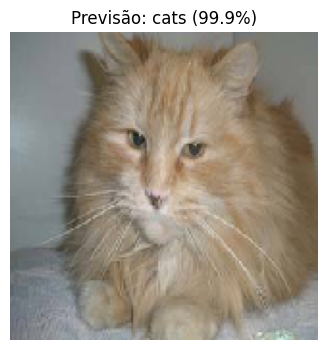

cats: 99.89%
dogs: 0.03%
panda: 0.08%


In [ ]:
# Troque pelo caminho real da imagem que deseja classificar.
caminho_imagem = '/content/drive/MyDrive/test_animals/cats/cats_00019.jpg'

if not Path(caminho_imagem).is_file():
    print('Imagem não encontrada. Atualize caminho_imagem para executar esta célula.')
else:
    imagem = keras.utils.load_img(caminho_imagem, target_size=TAMANHO_IMAGEM,
                                  color_mode='rgb')
    matriz_rgb = keras.utils.img_to_array(imagem)  # Valores 0 a 255.
    lote = np.expand_dims(matriz_rgb, axis=0)       # Forma (1, 160, 160, 3).

    # O preprocess_input da MobileNetV2 está dentro do modelo.
    probs = modelo.predict(lote, verbose=0)[0]
    indice = int(np.argmax(probs))

    plt.figure(figsize=(5, 4))
    plt.imshow(imagem)
    plt.title(f'Previsão: {CLASSES[indice]} ({probs[indice]:.1%})')
    plt.axis('off')
    plt.show()

    for nome, prob in zip(CLASSES, probs):
        print(f'{nome}: {prob:.2%}')

## 20. Salvar o modelo selecionado no Drive

In [ ]:
CAMINHO_SALVO = PASTA_DADOS.parent / 'mobilenetv2_gatos_cachorros_pandas.keras'
modelo.save(CAMINHO_SALVO)
print('Modelo salvo em:', CAMINHO_SALVO)